# Multispectral Sensor Characterization Using SPION Concentration Series — Data Analysis

## Overview

This notebook documents the analysis of the responses of three physical multispectral sensors to SPION suspensions at different iron concentrations.

The sensors were measured sequentially in three separate measurement series. Experimental steps were recorded in software-generated marker CSV files. Sensor signals and markers are aligned separately for each measurement series.

The analysis determines the mean ADC signal within each calibration window and summarizes three repeated measurements per concentration. Sensor responses are compared using the mean and sample standard deviation of the replicate means.

The stock suspension has an iron concentration of 5 mg Fe/mL, corresponding to a relative concentration of 100%. Model fitting is outside the scope of this initial analysis.

Differences between measurement series may reflect both sensor characteristics and differences in measurement conditions.

## Experimental Metadata

### Measurement Conditions

- **Experiment:** SPION concentration series
- **Operator:** Lukas Kroll
- **Location:** Laboratory A701, FH Dortmund
- **Measurement date:** 21 April 2026
- **Acquisition:** Three sequential static measurement series, one per physical sensor
- **Batch identifier:** XL004
- **Stock iron concentration:** 5 mg Fe/mL
- **Relative concentrations:** 0, 2.5, 5, 10, 25, 50, 75, and 100%
- **Warm-up time:** 20 min
- **min. sample time:** 60 s
- **Replicates:** Three measurements per concentration

Relative concentration is expressed as a percentage of the stock concentration. The corresponding iron concentration is calculated as:

$$
c_{\mathrm{Fe}} = \frac{c_{\mathrm{rel}}}{100}\,c_{\mathrm{stock}}, \qquad c_{\mathrm{stock}} = 5\,\mathrm{mg\,Fe\,mL^{-1}}.
$$

### Measurement Series

The physical sensor identity is assigned through the measurement-series documentation. The software ID recorded in the sensor CSV files is 1000 for all three series and therefore does not distinguish the physical devices.

| Physical sensor | Recorded software ID | Acquisition start, as recorded in the protocol |
|---|---|---|
| Sensor 0 | 1000 | 2026-04-21 10:38:26 |
| Sensor 1 | 1000 | 2026-04-21 12:48:24 |
| Sensor 2 | 1000 | 2026-04-21 14:23:54|

The protocol timestamps do not specify a time zone.

### Sensor Configuration

Acquisition settings were taken from the `Protocol_*.txt` file accompanying each measurement series. All three protocols report identical settings.

- **Device class:** SpectralSensor
- **Timeline band:** Band 9 (640 nm)
- **ATIME:** 0
- **ASTEP:** 8993
- **GAIN:** 1
- **IRMAIN:** 25
- **IROPP:** 25
- **VISM:** 255
- **VISLR:** 255
- **Signal unit:** ADC counts
- **Source timestamp unit:** Milliseconds

These settings are reported as recorded by the acquisition software. The interpretation of `GAIN` as a physical amplification factor and the conversion of `ATIME` and `ASTEP` to integration time require confirmation from the device configuration or driver documentation.

### Data Sources

Each measurement directory contains a sensor CSV file, a marker CSV file, and a protocol TXT file.

| Physical sensor | Measurement directory |
|---|---|
| Sensor 0 | `Sensor0_Messung_20260421_103826` |
| Sensor 1 | `Sensor1_Messung_20260421_124824` |
| Sensor 2 | `Sensor2_Messung_20260421_142354` |

- **Base directory:** `experiments/E01_sensor_calibration/data/`
- **Sensor measurements:** `SpectralSensor 1_<timestamp>.csv`
- **Experimental events:** `Markers_<timestamp>.csv`
- **Acquisition metadata:** `Protocol_<timestamp>.txt`

The sensor CSV filename is not used to infer physical sensor identity. Source files remain unchanged throughout the analysis.

## Analysis Parameters

- **Analyzed wavelength:** 640 nm
- **Calibration window:** 57 s after each selected marker
- **Signal statistic:** Arithmetic mean of valid ADC values within each window
- **Replicate summary:** Mean and sample standard deviation of three window means per concentration and sensor
- **Replicate weighting:** Equal weight for each window mean
- **Signal processing:** No baseline correction or reference normalization
- **Error bars:** Sample standard deviation between replicate means, not the standard deviation of individual samples within a window

### Figure Style

Colours and markers identify physical sensors consistently across figures, independently of recorded software IDs or sensor positions.

| Physical sensor | Colour | Hex code | Marker |
|---|---|---|---|
| Sensor 0 | Dark blue | `#004488` | Square |
| Sensor 1 | Ochre | `#DDAA33` | Circle |
| Sensor 2 | Rose | `#BB5566` | Triangle |


## Analysis Workflow

1. Read the sensor measurements and marker files for each measurement series.
2. Inspect data columns, missing values, and time ranges.
3. Establish a common time origin for each sensor measurement and its associated markers.
4. Plot the raw signals and inspect the calibration markers.
5. Assign calibration markers to known concentrations and replicate numbers.
6. Select and visually verify the calibration windows.
7. Calculate the valid sample count, mean ADC signal, and sample standard deviation within each window.
8. Summarize the three replicate means at each concentration.
9. Plot sensor response against iron concentration and compare the three sensors.
10. Export the result tables, figures, and analysis settings.

## Configuration

`measurement_series` links each physical sensor to its sensor file, marker file, protocol file, recorded software ID, and acquisition timestamp. `stock_concentration_mg_fe_ml` defines the stock iron concentration. `wavelength_nm`, `window_s`, and `expected_replicates` define the analysis settings. `sensor_styles` assigns consistent colours and markers to the physical sensors.

`Path()` constructs file paths relative to the notebook location. This configuration block defines inputs and settings; it does not read or modify the measurement files.


### Import PATH and LIB


`project_folder` identifies the repository root. `data_folder` contains the three calibration measurement series, and `output_folder` defines the destination for derived results. Adding the project folder to `sys.path` enables imports from `src.spectral_sensor`.

`read_sensor_csv()` and `read_marker_rows()` load measurement data. `read_protocol()` extracts the currently supported protocol metadata. `synchronize_time()` and `select_time_window()` prepare the time axes and calibration windows. `plot_timeseries()` displays the selected signals.

In [20]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

# Make the local pipeline available
project_folder = Path("..").resolve()

if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

# Data import
from src.spectral_sensor.io import (
    read_sensor_csv,
    read_marker_rows,
    read_protocol,
)

# Data preparation
from src.spectral_sensor.preprocessing import (
    synchronize_measurements,
    select_time_window,
    assign_markers,
)

# Plotting and export
from src.spectral_sensor.plotting import (
    plot_measurements,
    save_plot,
)

# Repository and data paths
project_folder = Path("..").resolve()
data_folder = project_folder / "experiments/E01_sensor_calibration/data"
output_folder = project_folder / "experiments/E01_sensor_calibration/results"



### Load Data

In [21]:
# Experimental metadata
experiment_id = "E01_sensor_calibration"
operator = "Lukas Kroll"
location = "Laboratory A701, FH Dortmund"

measurement_series = {
    "Sensor 0": {
        "physical_sensor_id": 0,
        "recorded_sensor_id": 1000,
        "folder": data_folder / "Sensor0_Messung_20260421_103826",
        "file_timestamp": "20260421_103826",
    },
    "Sensor 1": {
        "physical_sensor_id": 1,
        "recorded_sensor_id": 1000,
        "folder": data_folder / "Sensor1_Messung_20260421_124824",
        "file_timestamp": "20260421_124824",
    },
    "Sensor 2": {
        "physical_sensor_id": 2,
        "recorded_sensor_id": 1000,
        "folder": data_folder / "Sensor2_Messung_20260421_142354",
        "file_timestamp": "20260421_142354",
    },
}

# Analysis parameters
stock_concentration_mg_fe_ml = 5.0
wavelength_nm = 640
window_s = 57.0
expected_replicates = 3

# Tol High Contrast: physical sensor identities
sensor_styles = {
    "Sensor 0": {"color": "#004488", "marker": "s"},
    "Sensor 1": {"color": "#DDAA33", "marker": "o"},
    "Sensor 2": {"color": "#BB5566", "marker": "^"},
}

sensor_data = {}
marker_data = {}
protocol_metadata = {}

for sensor_name, measurement in measurement_series.items():
    folder = measurement["folder"]
    timestamp = measurement["file_timestamp"]

    sensor_file = folder / f"SpectralSensor 1_{timestamp}.csv"
    marker_file = folder / f"Markers_{timestamp}.csv"
    protocol_file = folder / f"Protocol_{timestamp}.txt"

    sensor_data[sensor_name] = read_sensor_csv(sensor_file)
    marker_data[sensor_name] = read_marker_rows(marker_file)
    protocol_metadata[sensor_name] = read_protocol(protocol_file)

pd.DataFrame.from_dict(protocol_metadata, orient="index")

,protocol_file,experiment_name,batch_number,start_time,timeline_band_nm,timeline_bands_nm
Sensor 0,Protocol_20260421_103826.txt,Sensor 0 Calibration,XL004,2026-04-21T10:38:26.888558,640,[640]
Sensor 1,Protocol_20260421_124824.txt,Sensor 1 Calibration,XL004,2026-04-21T12:48:24.226562,640,[640]
Sensor 2,Protocol_20260421_142354.txt,Sensor 2 Calibration,XL004,2026-04-21T14:23:54.114110,640,[640]


## Time Alignment

`synchronize_measurements()` aligns each sensor measurement with its corresponding marker file. `synced_sensors` and `synced_markers` contain the resulting tables with `time_s` in seconds relative to the start of each measurement series. Original timestamps are preserved.

In [22]:

from src.spectral_sensor.plotting import plot_measurements


synced_sensors, synced_markers = synchronize_measurements(
    sensor_data,
    marker_data,
)



## Calibration Marker Assignment

`calibration_markers` assigns each calibration event to a relative concentration and replicate number. The assignment is based on the recorded marker labels. The original marker index is retained for subsequent window selection.

`concentration_pct` expresses concentration relative to the stock suspension. `concentration_mg_fe_ml` gives the corresponding iron concentration.

In [23]:
from src.spectral_sensor.preprocessing import assign_markers
# Recorded calibration labels and their relative concentrations
concentrations = {
    "H20": 0.0,
    "C002": 2.5,
    "C005": 5.0,
    "C010": 10.0,
    "C025": 25.0,
    "C050": 50.0,
    "C075": 75.0,
    "C100": 100.0,
}

label_assignment = {}

for label, concentration in concentrations.items():
    for replicate in range(1, expected_replicates + 1):
        label_assignment[f"{label} - {replicate}"] = {
            "concentration_pct": concentration,
            "replicate": replicate,
        }
        
calibration_markers = assign_markers(
    synced_markers,
    label_assignment,
)

calibration_markers["concentration_mg_fe_ml"] = (
    calibration_markers["concentration_pct"]
    / 100
    * stock_concentration_mg_fe_ml
)

display(calibration_markers)

,sensor,marker_index,label,start_s,concentration_pct,replicate,concentration_mg_fe_ml
0,Sensor 0,4,H20 - 1,1274.794,0.0,1,0.000
1,Sensor 0,5,H20 - 2,1411.092,0.0,2,0.000
2,Sensor 0,6,H20 - 3,1544.221,0.0,3,0.000
3,Sensor 0,7,C002 - 1,1854.196,2.5,1,0.125
4,Sensor 0,8,C002 - 2,1975.126,2.5,2,0.125
...,...,...,...,...,...,...,...
67,Sensor 2,22,C075 - 2,5916.348,75.0,2,3.750
68,Sensor 2,23,C075 - 3,6005.091,75.0,3,3.750
69,Sensor 2,24,C100 - 1,6239.169,100.0,1,5.000
70,Sensor 2,25,C100 - 2,6323.266,100.0,2,5.000


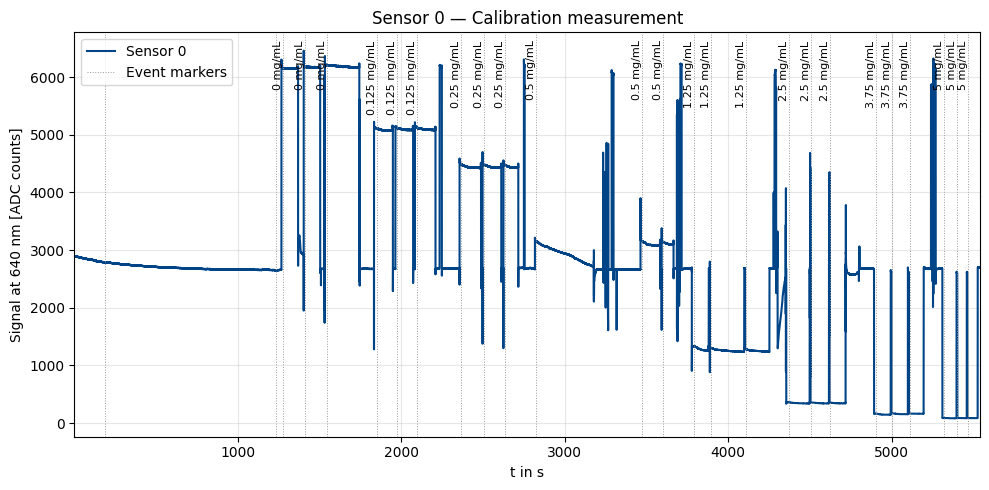

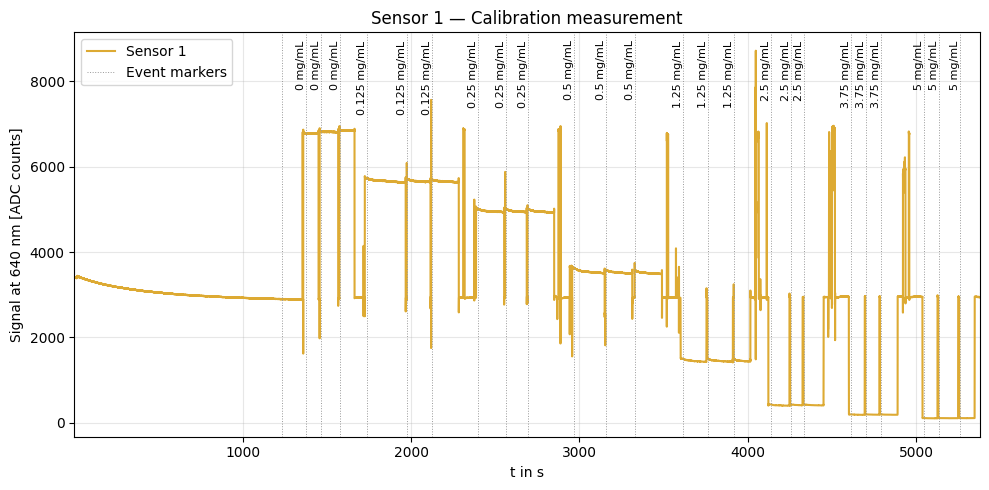

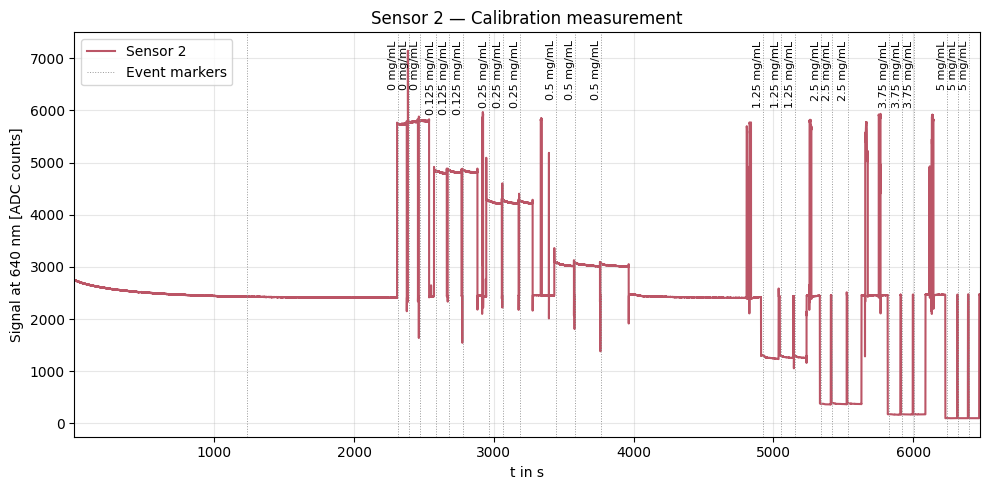

In [24]:
from src.spectral_sensor.plotting import plot_measurements, save_plot

for sensor_name in measurement_series:
    selected_markers = calibration_markers.loc[
        calibration_markers["sensor"] == sensor_name
    ]

    marker_labels = {}

    for _, marker in selected_markers.iterrows():
        concentration = marker["concentration_mg_fe_ml"]
        marker_labels[marker["marker_index"]] = (
            f"{concentration:g} mg/mL"
        )

    fig, ax = plot_measurements(
        {sensor_name: synced_sensors[sensor_name]},
        synced_markers[sensor_name],
        marker_labels=marker_labels,
        time_column="time_s",
        signal_column=str(wavelength_nm),
        xlabel="t in s",
        ylabel=f"Signal at {wavelength_nm} nm [ADC counts]",
        title=f"{sensor_name.replace('_', ' ').capitalize()} — Calibration measurement",
        sensor_styles=sensor_styles,
    )

    save_plot(
        fig,
        output_folder=output_folder / "figures",
        filename=f"{sensor_name}_raw_{wavelength_nm}nm",
    )

## Signal Statistics per Calibration Window

`summarize_windows()` selects a window of duration `window_s` after each assigned marker and calculates the arithmetic mean and sample standard deviation of the selected signal.

`window_statistics` retains the marker assignments and reports `n_samples`, `mean_signal`, and `std_signal`. For the selected raw channel, signal statistics are expressed in ADC counts. Missing or non-numeric signal values are excluded. The standard deviation describes variability within a window, not variability between replicates. A single valid sample yields a standard deviation of zero by convention; an empty window yields missing statistics.

In [ ]:
windows = {}
results = []

for _, marker in calibration_markers.iterrows():
    sensor_name = marker["sensor"]
    marker_index = marker["marker_index"]

    window = select_time_window(
        {sensor_name: synced_sensors[sensor_name]},
        start_s=marker["start_s"],
        window_s=window_s,
    )[sensor_name]

    windows[(sensor_name, marker_index)] = window

    signal = pd.to_numeric(
        window[str(wavelength_nm)], errors="coerce"
    ).dropna()

    results.append({
        "sensor": sensor_name,
        "marker_index": marker_index,
        "concentration_mg_fe_ml": marker["concentration_mg_fe_ml"],
        "replicate": marker["replicate"],
        "n_samples": len(signal),
        "mean_signal": signal.mean(),
        "std_signal": signal.std(ddof=1),
    })

window_statistics = pd.DataFrame(results)
display(window_statistics)


,sensor,marker_index,concentration_mg_fe_ml,replicate,n_samples,mean_signal,std_signal
0,Sensor 0,4,0.000,1,753,6151.407703,2.800987
1,Sensor 0,5,0.000,2,753,6174.051793,3.359446
2,Sensor 0,6,0.000,3,753,6201.794157,4.054662
3,Sensor 0,7,0.125,1,753,5084.962815,10.877886
4,Sensor 0,8,0.125,2,753,5097.872510,10.806184
...,...,...,...,...,...,...,...
67,Sensor 2,22,3.750,2,749,174.176235,1.599940
68,Sensor 2,23,3.750,3,749,173.455274,1.255869
69,Sensor 2,24,5.000,1,749,100.558077,1.555877
70,Sensor 2,25,5.000,2,749,100.504673,0.538906


## Calibration Results

`calibration_summary` reports the mean and sample standard deviation of the replicate window means for each sensor and iron concentration. `n_replicates` indicates the number of valid window means included. Signal statistics are expressed in ADC counts.

In [ ]:
calibration_summary = (
    window_statistics
    .groupby(["sensor", "concentration_mg_fe_ml"], as_index=False)
    .agg(
        n_replicates=("mean_signal", "count"),
        mean_adc=("mean_signal", "mean"),
        std_adc=("mean_signal", "std"),
    )
)

display(calibration_summary.round(2))

output_folder.mkdir(parents=True, exist_ok=True)

calibration_summary.to_csv(
    output_folder / f"calibration_summary_{wavelength_nm}nm.csv",
    index=False,
)

,sensor,concentration_mg_fe_ml,n_replicates,mean_adc,std_adc
0,Sensor 0,0.00,3,6175.75,25.24
1,Sensor 0,0.12,3,5095.25,9.26
2,Sensor 0,0.25,3,4450.42,5.92
3,Sensor 0,0.50,3,3109.02,6.65
4,Sensor 0,1.25,3,1277.47,14.97
5,Sensor 0,2.50,3,349.67,2.23
6,Sensor 0,3.75,3,158.51,5.70
7,Sensor 0,5.00,3,87.77,2.86
8,Sensor 1,0.00,3,6807.27,37.04
9,Sensor 1,0.12,3,5678.24,13.50


## Sensor Response Comparison

The figure shows mean ADC signal versus iron concentration for all three physical sensors. Each point represents the mean of the replicate window means.

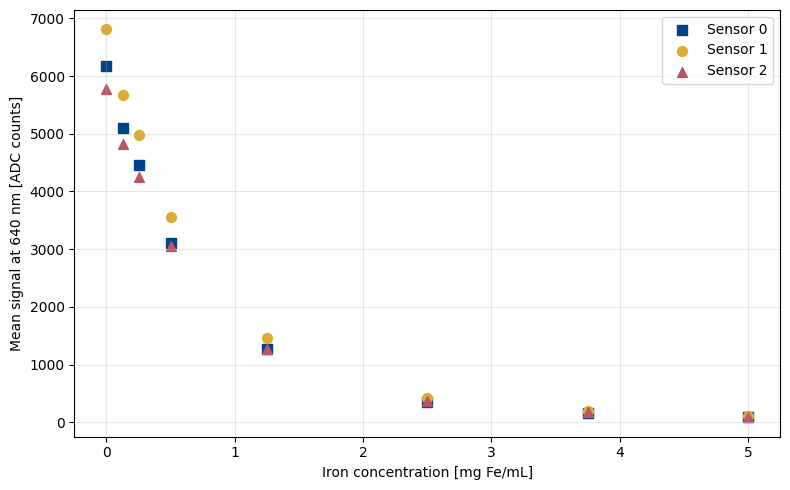

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for sensor_name, table in calibration_summary.groupby("sensor"):
    style = sensor_styles[sensor_name]

    ax.scatter(
        table["concentration_mg_fe_ml"],
        table["mean_adc"],
        marker=style["marker"],
        color=style["color"],
        s=50,
        label=sensor_name.replace("_", " ").capitalize(),
    )

ax.set_xlabel("Iron concentration [mg Fe/mL]")
ax.set_ylabel(f"Mean signal at {wavelength_nm} nm [ADC counts]")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

save_plot(
    fig,
    output_folder=output_folder / "figures",
    filename=f"sensor_response_comparison_{wavelength_nm}nm",
)